id: notebooks/E_coordinates.ipynb

coordinate frames: equatorial (RA/Dec, hour angle, sidereal time), horizontal (azimuth/elevation, parallactic angle), WGS84/ECEF/ENU, the baseline vector, uvw and the uv-ellipse, delay and w, precession

<!-- notebooks/E_coordinates.ipynb -- theory E: coordinate frames (Interferosim 0.9.4) -->
# E – Coordinate frames

---
  DI Erich Schubert, 07925151
  


*Theory notebook E.* An interferometer connects three kinds of coordinates: the **sky** (right ascension and declination), the **Earth** (geodetic positions of the stations, the baseline vector) and the **instrument** (uvw, the geometric delay, the direction of the antennas). The package computes everything in one earth-fixed frame (ECEF, module `observation.geometry`); this notebook takes the frames apart one by one and checks the package against the classical formulas.

Package: `gmst_deg`, `gha_deg`, `sky_basis`, `direction`, `uvw`, `geometric_delay`, `elevation_deg`, `geodetic_to_ecef`, `ecef_to_enu_matrix`, `Station.from_enu`; new in 0.9.4 `lst_deg`, `azimuth_elevation_deg`, `parallactic_angle_deg`, `precess_deg`.

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from interferosim.constants import C_LIGHT, HI_21CM
from interferosim.instrument import Site, Station, Array, geodetic_to_ecef, ecef_to_enu_matrix, ecef_to_geodetic
from interferosim.sky import SkyModel
from interferosim.observation import (gmst_deg, gha_deg, lst_deg, sky_basis, direction, uvw, geometric_delay,
                                      elevation_deg, azimuth_elevation_deg, parallactic_angle_deg, precess_deg,
                                      mjd_from_iso, sun_radec_deg)

CFG = Path("..") / "configs"
DATE = "2026-11-01"
LAM = C_LIGHT / HI_21CM
site = Site.from_toml(CFG / "sites" / "wilhelmsburg.toml")
SOURCES = {n: SkyModel.from_json(CFG / "skies" / f"{f}.json").center for n, f in
           (("Cas A", "cas_a"), ("Cyg A", "cyg_a"), ("Tau A", "tau_a"), ("Vir A", "vir_a"), ("W3(OH)", "w3oh_masers"))}
unix = lambda iso: (mjd_from_iso(iso) - 40587.0) * 86400.0
print(f"site {site.name}: lat {site.lat_deg:.6f}°, lon {site.lon_deg:.6f}° E, h {site.alt_m:.0f} m")

site Wilhelmsburg: lat 48.088056°, lon 15.756111° E, h 280 m


## 1. Equatorial coordinates and sidereal time

A source keeps its **right ascension** α and **declination** δ (J2000 catalogue frame) while the Earth turns underneath. What counts for the observer is the **hour angle**

$$H = \mathrm{LST} - \alpha, \qquad \mathrm{LST} = \mathrm{GMST} + \lambda_\mathrm{east},$$

with the Greenwich mean sidereal time (IAU 1982 formula in `gmst_deg`). The sidereal day is 23 h 56 min 4 s: a source transits about 4 minutes earlier every day. $H = 0$: upper transit (highest elevation), $H = \pm 6$ h: six sidereal hours before/after.

In [2]:
t0 = unix(DATE + "T20:00:00")
lst = float(lst_deg(t0, site.lon_deg))
print(f"{DATE} 20:00 UTC: GMST {float(gmst_deg(t0)) / 15:.4f} h, LST at Wilhelmsburg {lst / 15:.4f} h\n")
print(f"{'source':<8s} {'RA [h]':>8s} {'Dec [deg]':>10s} {'H [h]':>7s} {'elevation':>10s} {'azimuth':>8s}")
for name, c in SOURCES.items():
    H = ((lst - c.ra_deg + 180) % 360 - 180) / 15
    s = direction(c.dec_deg, gha_deg(c.ra_deg, t0))
    az, el = azimuth_elevation_deg(s, site.lat_deg, site.lon_deg)
    print(f"{name:<8s} {c.ra_deg / 15:8.3f} {c.dec_deg:10.3f} {H:7.2f} {float(el):9.1f}° {float(az):7.1f}°")
shift = 24 * (1 - 0.99726957) * 60
print(f"\nthe transit moves {shift:.2f} min earlier every day (sidereal day = {24 * 0.99726957:.4f} h)")

2026-11-01 20:00 UTC: GMST 22.7413 h, LST at Wilhelmsburg 23.7917 h

source     RA [h]  Dec [deg]   H [h]  elevation  azimuth
Cas A      23.390     58.815    0.40      78.7°   343.9°
Cyg A      19.991     40.734    3.80      49.6°   281.5°
Tau A       5.576     22.015   -5.78      18.3°    77.1°
Vir A      12.514     12.391   11.28     -28.8°   347.9°
W3(OH)      2.451     61.874   -2.66      63.9°    43.4°

the transit moves 3.93 min earlier every day (sidereal day = 23.9345 h)


## 2. The horizontal system

Azimuth (from north through east) and elevation follow from $H$, δ and the latitude φ:

$$\sin e = \sin\varphi\sin\delta + \cos\varphi\cos\delta\cos H, \qquad \tan A = \frac{-\cos\delta\sin H}{\sin\delta\cos\varphi - \cos\delta\cos H\sin\varphi}.$$

The package does it in vectors: `direction` gives the unit vector in ECEF, `azimuth_elevation_deg` projects it on east, north and up of the site. Sources with $\delta > 90° - \varphi$ (here 41.9°) are **circumpolar**. The **parallactic angle** $q$ is the angle between north on the sky and the vertical: the sky turns by $q$ in an antenna on an alt-azimuth mount – the polarisation angle of a fixed Yagi changes with it.

Cas A   : max |elevation(package) - classical formula| = 5.7e-14 deg; circumpolar
Cyg A   : max |elevation(package) - classical formula| = 8.5e-14 deg; up 21.8 h per day
Tau A   : max |elevation(package) - classical formula| = 5.0e-14 deg; up 15.5 h per day
Vir A   : max |elevation(package) - classical formula| = 4.6e-14 deg; up 13.9 h per day
W3(OH)  : max |elevation(package) - classical formula| = 4.3e-14 deg; circumpolar


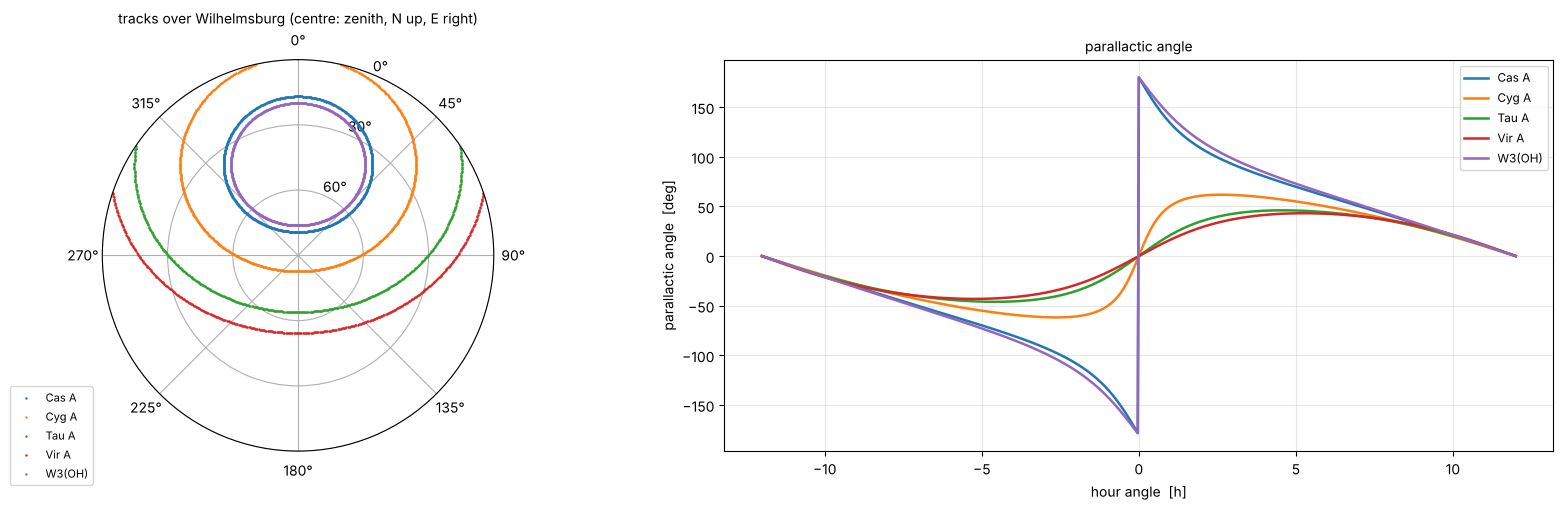

In [3]:
ha = np.linspace(-180, 180, 721)
fig = plt.figure(figsize=(17, 5.2))
axp = fig.add_subplot(1, 2, 1, projection="polar")
axq = fig.add_subplot(1, 2, 2)
for name, c in SOURCES.items():
    s = direction(c.dec_deg, np.mod(ha - site.lon_deg, 360))
    az, el = azimuth_elevation_deg(s, site.lat_deg, site.lon_deg)
    up = el > 0
    axp.plot(np.radians(az[up]), 90 - el[up], ".", ms=1.5, label=name)
    axq.plot(ha / 15, parallactic_angle_deg(ha, c.dec_deg, site.lat_deg), lw=1.8, label=name)
    # formula check against the classical expressions
    e_cl = np.degrees(np.arcsin(np.sin(np.radians(site.lat_deg)) * np.sin(np.radians(c.dec_deg))
                                + np.cos(np.radians(site.lat_deg)) * np.cos(np.radians(c.dec_deg)) * np.cos(np.radians(ha))))
    print(f"{name:<8s}: max |elevation(package) - classical formula| = {np.max(np.abs(el - e_cl)):.1e} deg; "
          f"{'circumpolar' if c.dec_deg > 90 - site.lat_deg else f'up {np.mean(up) * 24:.1f} h per day'}")
axp.set_theta_zero_location("N"); axp.set_theta_direction(-1); axp.set_rlim(0, 90)
axp.set_rticks([0, 30, 60, 90]); axp.set_yticklabels(["90°", "60°", "30°", "0°"])
axp.set_title("tracks over Wilhelmsburg (centre: zenith, N up, E right)", fontsize=10)
axp.legend(fontsize=8, loc="lower left", bbox_to_anchor=(-0.25, -0.1))
axq.set(xlabel="hour angle  [h]", ylabel="parallactic angle  [deg]", title="parallactic angle")
axq.grid(alpha=0.3); axq.legend(fontsize=8.5); axq.title.set_fontsize(10)
fig.tight_layout(); plt.show()

## 3. The Earth: WGS84, ECEF and ENU

Station positions are given geodetically (latitude, longitude, height on the WGS84 ellipsoid). For the geometry they are converted to the earth-centred, earth-fixed frame **ECEF** (X through the Greenwich meridian on the equator, Z through the north pole). Local offsets are easier in **ENU** (east, north, up) at the site; the rotation matrix `ecef_to_enu_matrix` converts between the two.

The **baseline** is the ECEF difference of two stations. Its components along the Earth's axis ($L_Z$) and in the equatorial plane ($L_X$, $L_Y$) decide the uv-coverage: the equatorial part rotates with the Earth, the axial part does not.

In [4]:
east_st = Station.from_enu("X", site, 11_500, 0, 0)
north_st = Station.from_enu("N", site, 0, 11_500, 0)
ref = Station.from_enu("W", site, 0, 0, 0)
R = ecef_to_enu_matrix(site.lat_deg, site.lon_deg)
print(f"Wilhelmsburg ECEF: {np.round(site.ecef_m() / 1e3, 3)} km (|r| = {np.linalg.norm(site.ecef_m()) / 1e3:.3f} km)\n")
print(f"{'baseline':<22s} {'ENU [m]':>28s} {'ECEF L_X, L_Y, L_Z [m]':>32s} {'length':>9s}")
for name, st in (("11.5 km east-west", east_st), ("11.5 km north-south", north_st)):
    b = st.ecef_m() - ref.ecef_m()
    enu = R @ b
    print(f"{name:<22s} {np.array2string(np.round(enu, 1), separator=', '):>28s} {np.array2string(np.round(b, 1), separator=', '):>32s} {np.linalg.norm(b):8.1f} m")
lat2, lon2, h2 = ecef_to_geodetic(*east_st.ecef_m())
print(f"\nthe east station: lat {lat2:.6f}°, lon {lon2:.6f}° (Δlon {lon2 - site.lon_deg:.5f}° = 11.5 km / (R cos φ)), "
      f"h {h2:.1f} m (the tangent plane rises {h2 - site.alt_m:.1f} m above the ellipsoid at 11.5 km)")
print("east-west: L_Z ≈ 0, the baseline lies in the equatorial plane; north-south: L_Z = B cos φ ≠ 0.")

Wilhelmsburg ECEF: [4108.236 1159.115 4723.631] km (|r| = 6366.619 km)

baseline                                    ENU [m]           ECEF L_X, L_Y, L_Z [m]    length
11.5 km east-west          [11500.,     0.,    -0.]      [-3122.7, 11067.9,     0. ]  11500.0 m
11.5 km north-south        [    0., 11500.,     0.]      [-8236.4, -2323.9,  7681.9]  11500.0 m

the east station: lat 48.087952°, lon 15.910470° (Δlon 0.15436° = 11.5 km / (R cos φ)), h 290.3 m (the tangent plane rises 10.3 m above the ellipsoid at 11.5 km)
east-west: L_Z ≈ 0, the baseline lies in the equatorial plane; north-south: L_Z = B cos φ ≠ 0.


## 4. uvw and the uv-ellipse

The package projects the baseline (ECEF) on the sky basis of the phase centre: $u$ on east, $v$ on north, $w$ on the direction $\hat s_0$ (`sky_basis`, `uvw`). With the Greenwich hour angle $H$ these are the classical expressions (Thompson, Moran & Swenson),

$$\begin{pmatrix}u\\v\\w\end{pmatrix} = \frac{1}{\lambda}\begin{pmatrix} \sin H & \cos H & 0\\ -\sin\delta\cos H & \sin\delta\sin H & \cos\delta\\ \cos\delta\cos H & -\cos\delta\sin H & \sin\delta\end{pmatrix}\begin{pmatrix}L_X\\L_Y\\L_Z\end{pmatrix},$$

and over the day $(u, v)$ traces the ellipse

$$\frac{u^2}{a^2} + \frac{(v - v_0)^2}{(a\sin\delta)^2} = 1, \qquad a = \frac{\sqrt{L_X^2+L_Y^2}}{\lambda},\quad v_0 = \frac{L_Z\cos\delta}{\lambda}.$$

East–west baselines ($L_Z = 0$) give ellipses centred on the origin, flattening towards the celestial equator; a north–south component shifts the ellipse in $v$.

11.5 km east-west, δ = +61.9°: |package - classical| = 1.5e-11 λ, ellipse equation 1 ± 8.9e-16, centre v0 = +0.00 kλ
11.5 km east-west, δ = +40.7°: |package - classical| = 1.5e-11 λ, ellipse equation 1 ± 8.9e-16, centre v0 = +0.00 kλ
11.5 km east-west, δ = +22.0°: |package - classical| = 1.5e-11 λ, ellipse equation 1 ± 6.7e-16, centre v0 = +0.00 kλ
11.5 km east-west, δ =  -5.0°: |package - classical| = 1.5e-11 λ, ellipse equation 1 ± 6.7e-16, centre v0 = +0.00 kλ
11.5 km north-south, δ = +61.9°: |package - classical| = 1.5e-11 λ, ellipse equation 1 ± 6.7e-16, centre v0 = +17.14 kλ
11.5 km north-south, δ = +40.7°: |package - classical| = 1.5e-11 λ, ellipse equation 1 ± 8.9e-16, centre v0 = +27.59 kλ
11.5 km north-south, δ = +22.0°: |package - classical| = 1.5e-11 λ, ellipse equation 1 ± 1.0e-15, centre v0 = +33.75 kλ
11.5 km north-south, δ =  -5.0°: |package - classical| = 1.5e-11 λ, ellipse equation 1 ± 4.3e-15, centre v0 = +36.26 kλ


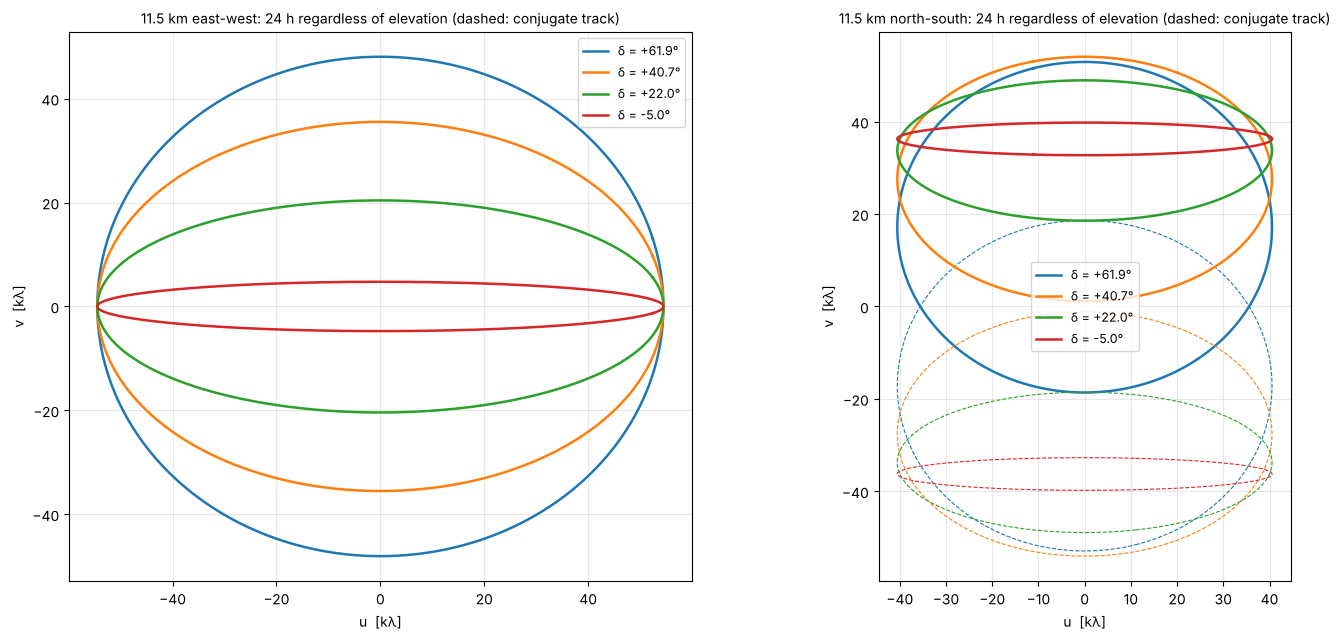

In [5]:
g = np.linspace(0, 360, 721)
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, (name, st) in zip(axes, (("11.5 km east-west", east_st), ("11.5 km north-south", north_st))):
    L = st.ecef_m() - ref.ecef_m()
    for dec, col in ((61.9, "C0"), (40.7, "C1"), (22.0, "C2"), (-5.0, "C3")):
        q = uvw(L, dec, g, LAM)
        h = np.radians(g); d = np.radians(dec)
        u_cl = (np.sin(h) * L[0] + np.cos(h) * L[1]) / LAM
        v_cl = (-np.sin(d) * np.cos(h) * L[0] + np.sin(d) * np.sin(h) * L[1] + np.cos(d) * L[2]) / LAM
        err = max(np.max(np.abs(q[:, 0] - u_cl)), np.max(np.abs(q[:, 1] - v_cl)))
        a = np.hypot(L[0], L[1]) / LAM; v0 = L[2] * np.cos(d) / LAM
        ell = (q[:, 0] / a) ** 2 + ((q[:, 1] - v0) / (a * np.sin(d))) ** 2
        ax.plot(q[:, 0] / 1e3, q[:, 1] / 1e3, color=col, lw=1.8, label=f"δ = {dec:+.1f}°")
        ax.plot(-q[:, 0] / 1e3, -q[:, 1] / 1e3, color=col, lw=0.8, ls="--")
        print(f"{name}, δ = {dec:+5.1f}°: |package - classical| = {err:.1e} λ, ellipse equation 1 ± {np.max(np.abs(ell - 1)):.1e}, "
              f"centre v0 = {v0 / 1e3:+.2f} kλ")
    ax.set(xlabel="u  [kλ]", ylabel="v  [kλ]", title=f"{name}: 24 h regardless of elevation (dashed: conjugate track)", aspect="equal")
    ax.grid(alpha=0.3); ax.legend(fontsize=9); ax.title.set_fontsize(10)
fig.tight_layout(); plt.show()

## 5. Geometric delay and w

The wavefront reaches the stations at different times. With the package convention $\tau = -(\vec B\cdot\hat s)/c$ (positive: station $j$ later than the reference) the delay is the $w$ component in time units, $\tau = -w\lambda/c$. Its maximum is $B/c$ (38 µs for 11.5 km); its rate – the fringe rate divided by the frequency – follows from the Earth's rotation.

max |tau + w λ/c| = 3.4e-21 s; max |tau| over ±6 h = 29.07 µs (B/c = 38.36 µs)


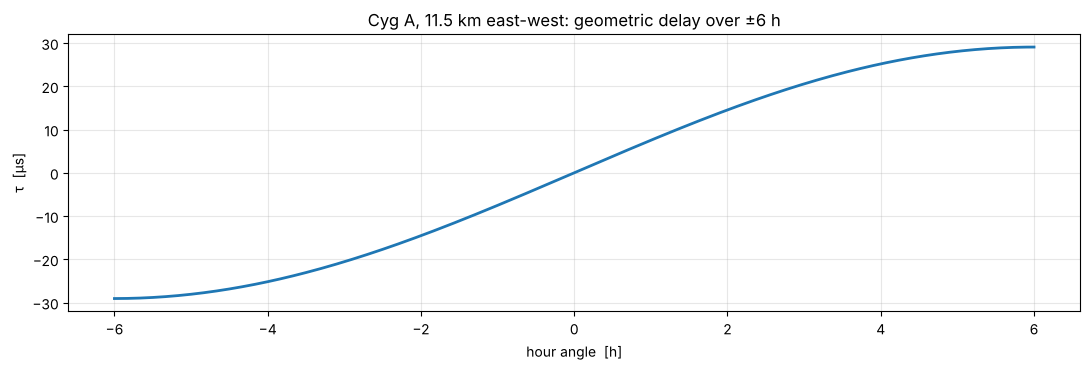

In [6]:
L = east_st.ecef_m() - ref.ecef_m()
c = SOURCES["Cyg A"]
gg = np.mod(np.linspace(-90, 90, 361) - site.lon_deg, 360)
tau = geometric_delay(L, direction(c.dec_deg, gg))
w = uvw(L, c.dec_deg, gg, LAM)[:, 2]
print(f"max |tau + w λ/c| = {np.max(np.abs(tau + w * LAM / C_LIGHT)):.1e} s; max |tau| over ±6 h = {np.max(np.abs(tau)) * 1e6:.2f} µs "
      f"(B/c = {np.linalg.norm(L) / C_LIGHT * 1e6:.2f} µs)")
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(np.linspace(-6, 6, 361), tau * 1e6, lw=2)
ax.set(xlabel="hour angle  [h]", ylabel="τ  [µs]", title="Cyg A, 11.5 km east-west: geometric delay over ±6 h"); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

## 6. Epochs: precession

Catalogue coordinates refer to the mean equator and equinox J2000.0. The Earth's axis precesses by 50″ per year; on 2026-11-01 the coordinates of date differ by about 0.3°. `precess_deg` applies the IAU 1976 precession (checked against astropy: 0.1″). The simulators of the package use the catalogue coordinates directly with the GMST of the date – self-consistent, because the simulated correlator uses the same model. **For real recordings** the delay model must use the coordinates of date (plus nutation and aberration, ≈ 20″): the difference below is the delay and position error that would otherwise have to be absorbed by the fringe search.

In [7]:
mjd = mjd_from_iso(DATE + "T20:00:00")
print(f"{'source':<8s} {'ΔRA cos δ [arcsec]':>19s} {'ΔDec [arcsec]':>14s} {'total [deg]':>12s} {'max delay error, 11.5 km':>26s}")
for name, c in SOURCES.items():
    ra2, dec2 = (float(x) for x in precess_deg(c.ra_deg, c.dec_deg, mjd))
    dra = ((ra2 - c.ra_deg + 180) % 360 - 180) * np.cos(np.radians(c.dec_deg)) * 3600
    ddec = (dec2 - c.dec_deg) * 3600
    gg = np.mod(np.linspace(0, 360, 721), 360)
    dtau = geometric_delay(L, direction(dec2, np.mod(gg - (ra2 - c.ra_deg), 360))) - geometric_delay(L, direction(c.dec_deg, gg))
    print(f"{name:<8s} {dra:19.0f} {ddec:14.0f} {np.hypot(dra, ddec) / 3600:12.3f} {np.max(np.abs(dtau)) * 1e9:22.0f} ns")
print("\n(the GHA of a source is GMST - RA: with the precessed RA the hour angle shifts by ΔRA. The delay error,")
print(" up to B Δθ / c ≈ 250 ns, is as large as half the delay beam of 2 MHz and corresponds to some 350 turns of the")
print(" fringe phase at 1420 MHz, changing over the day - the fringe search would have to absorb it.)")

source    ΔRA cos δ [arcsec]  ΔDec [arcsec]  total [deg]   max delay error, 11.5 km
Cas A                    569            531        0.216                    135 ns
Cyg A                    634            269        0.191                    122 ns
Tau A                   1348             58        0.375                    251 ns
Vir A                   1193           -533        0.363                    223 ns
W3(OH)                   870            429        0.269                    176 ns

(the GHA of a source is GMST - RA: with the precessed RA the hour angle shifts by ΔRA. The delay error,
 up to B Δθ / c ≈ 250 ns, is as large as half the delay beam of 2 MHz and corresponds to some 350 turns of the
 fringe phase at 1420 MHz, changing over the day - the fringe search would have to absorb it.)


## 7. Summary

| frame | coordinates | package |
|---|---|---|
| equatorial (J2000) | α, δ; hour angle $H$ = LST − α | `gmst_deg`, `lst_deg`, `gha_deg` |
| equatorial of date | precessed α, δ | `precess_deg` |
| horizontal | azimuth, elevation, parallactic angle | `azimuth_elevation_deg`, `elevation_deg`, `parallactic_angle_deg` |
| geodetic | φ, λ, h (WGS84) | `Site`, `Station`, `ecef_to_geodetic` |
| ECEF | X, Y, Z; baseline $L_X, L_Y, L_Z$ | `geodetic_to_ecef`, `Station.ecef_m`, `Array.baselines` |
| ENU | east, north, up at the site | `ecef_to_enu_matrix`, `Station.from_enu` |
| sky basis | $\hat s_0$, $e_E$, $e_N$ at the phase centre | `sky_basis`, `direction` |
| interferometer | u, v, w [λ]; τ = −wλ/c | `uvw`, `geometric_delay`, `delay_rate` |

## 8. Selector

Declination, baseline length and azimuth, latitude and hour-angle range; *Run Interact* shows the uv-track, the elevation and the parallactic angle. (Needs a running kernel.)

In [8]:
import ipywidgets as widgets
from IPython.display import display

def run_coords(dec_deg, baseline_km, azimuth_deg, lat_deg, ha_half_h):
    s = Site("site", lat_deg, site.lon_deg, 280.0)
    a_r = np.radians(azimuth_deg)
    r0 = Station.from_enu("A", s, 0, 0, 0)
    r1 = Station.from_enu("B", s, 1e3 * baseline_km * np.sin(a_r), 1e3 * baseline_km * np.cos(a_r), 0)
    Lv = r1.ecef_m() - r0.ecef_m()
    hh = np.linspace(-ha_half_h * 15, ha_half_h * 15, 400)
    gg = np.mod(hh - s.lon_deg, 360)
    q = uvw(Lv, dec_deg, gg, LAM)
    el = elevation_deg(direction(dec_deg, gg), s.lat_deg, s.lon_deg)
    up = el > 10
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
    axes[0].plot(q[:, 0] / 1e3, q[:, 1] / 1e3, color="0.8", lw=1)
    axes[0].plot(q[up, 0] / 1e3, q[up, 1] / 1e3, "C0.", ms=2); axes[0].plot(-q[up, 0] / 1e3, -q[up, 1] / 1e3, "C1.", ms=2)
    axes[0].set(xlabel="u [kλ]", ylabel="v [kλ]", aspect="equal", title=f"uv-track (grey: below 10°), L_Z = {Lv[2]:.0f} m")
    axes[1].plot(hh / 15, el); axes[1].axhline(10, color="k", ls=":"); axes[1].set(xlabel="hour angle [h]", ylabel="elevation [deg]")
    axes[2].plot(hh / 15, parallactic_angle_deg(hh, dec_deg, lat_deg)); axes[2].set(xlabel="hour angle [h]", ylabel="parallactic angle [deg]")
    for ax in axes: ax.grid(alpha=0.3); ax.title.set_fontsize(10)
    fig.tight_layout(); plt.show()

display(widgets.interactive(
    run_coords, {"manual": True},
    dec_deg=widgets.FloatSlider(value=40.7, min=-40, max=89, step=0.5, description="Dec [deg]"),
    baseline_km=widgets.FloatSlider(value=11.5, min=0.01, max=50, step=0.01, description="B [km]"),
    azimuth_deg=widgets.FloatSlider(value=90, min=0, max=180, step=1, description="azimuth [deg]"),
    lat_deg=widgets.FloatSlider(value=site.lat_deg, min=-80, max=80, step=0.5, description="latitude"),
    ha_half_h=widgets.FloatSlider(value=12, min=0.5, max=12, step=0.5, description="±HA [h]"),
))

interactive(children=(FloatSlider(value=40.7, description='Dec [deg]', max=89.0, min=-40.0, step=0.5), FloatSl…